# NB 3/6 · Markov Decision Process (MDP)

---
### References
[Be] Bellman R. (1957) *Dynamic Programming.* Princeton Univ. Press  
[Ho] Howard R.A. (1960) *Dynamic Programming and Markov Processes.* MIT Press  
[Pu] Puterman M.L. (1994) *Markov Decision Processes.* Wiley *(Theorems 6.3.1, 6.4.1)*

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from shared_data import print_metrics
import warnings; warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,
                     'axes.spines.right':False,'font.size':11})
STAGE_NAMES=['W','N1','N2','N3','REM']; N_STAGES=5; N_ACTIONS=3
ACTION_NAMES=['low_power','balanced','high_precision']
STAGE_COLORS={'W':'#4c78a8','N1':'#f58518','N2':'#54a24b',
              'N3':'#e45756','REM':'#b279a2'}
T=np.load('T.npy'); y_tr=np.load('y_tr.npy'); y_te=np.load('y_te.npy')
class_w=np.load('class_w.npy')
print('MDP artefacts loaded.')

MDP artefacts loaded.


## §1 — MDP Tuple $(\mathcal{S},\mathcal{A},P,R,\gamma)$

| Symbol | Element | Value |
|---|---|---|
| $\mathcal{S}$ | States | $\{W,N1,N2,N3,REM\}$ |
| $\mathcal{A}$ | Actions | $\{\text{low\_power, balanced, high\_precision}\}$ |
| $P(s'\mid s,a)$ | Transition | DTMC matrix $\hat{T}$ (action-independent) |
| $R(s,a)$ | Reward | clinical benefit − energy cost + rarity bonus |
| $\gamma=0.95$ | Discount | effective horizon $\approx 1/(1-\gamma)=20$ steps |

### Reward design with rarity bonus

To prevent the agent from ignoring rare stages, each state $s$ receives a bonus proportional to its inverse-frequency weight:
$$R(s,a)=R_{\text{base}}(s,a)-c_{\text{energy}}(a)+\eta\,\tilde{w}_s$$

where $\tilde{w}_s = w_s/\max_k w_k$ and $\eta=0.15$. Rare stages (N1, N3) therefore attract higher reward, incentivising the policy to choose high-precision monitoring for them.

In [2]:
norm_w = class_w / class_w.max()

def reward_matrix(eta=0.15):
    R = np.zeros((N_STAGES, N_ACTIONS))
    base = {(0,0):.90,(0,1):.60,(0,2):.30,
            (1,0):.30,(1,1):.75,(1,2):.90,
            (2,0):.90,(2,1):.60,(2,2):.30,
            (3,0):.40,(3,1):.80,(3,2):.95,
            (4,0):.20,(4,1):.80,(4,2):1.00}
    for (s,a), v in base.items(): R[s,a] = v
    R -= np.array([.05, .10, .20])   # energy cost per action
    for s in range(N_STAGES): R[s,:] += eta * norm_w[s]
    return R

R_mdp = reward_matrix()
P_mdp = np.stack([T]*N_ACTIONS, axis=2)  # transition same for all actions

print('Reward matrix R(s,a) with rarity bonus (eta=0.15):')
print(pd.DataFrame(R_mdp, index=STAGE_NAMES, columns=ACTION_NAMES).round(3).to_string())
print()
print('Rarity bonuses per stage:')
for i,s in enumerate(STAGE_NAMES):
    print(f'  {s:>4}: +{0.15*norm_w[i]:.3f}  (class weight={class_w[i]:.3f})')

Reward matrix R(s,a) with rarity bonus (eta=0.15):
     low_power  balanced  high_precision
W        0.925     0.575           0.175
N1       0.400     0.800           0.850
N2       0.925     0.575           0.175
N3       0.425     0.775           0.825
REM      0.225     0.775           0.875

Rarity bonuses per stage:
     W: +0.075  (class weight=0.900)
    N1: +0.150  (class weight=1.800)
    N2: +0.075  (class weight=0.900)
    N3: +0.075  (class weight=0.900)
   REM: +0.075  (class weight=0.900)


## §2 — Value Iteration [Be]

Starting from $V_0(s)=0$, the Bellman optimality operator:
$$V_{k+1}(s)=\max_a\!\left[R(s,a)+\gamma\sum_{s'}P(s'\mid s,a)\,V_k(s')\right]$$

converges to $V^*$ with error bound $\|V_k-V^*\|_\infty\le\gamma^k/(1-\gamma)$ [Pu Thm 6.3.1].

The optimal Q-function:
$$Q^*(s,a)=R(s,a)+\gamma\sum_{s'}P(s'\mid s,a)\,V^*(s')$$

## §3 — Policy Iteration [Ho]

Alternates between exact policy evaluation:
$$(I-\gamma P_\pi)V_\pi=R_\pi \quad\Rightarrow\quad V_\pi=(I-\gamma P_\pi)^{-1}R_\pi$$

and greedy policy improvement:
$$\pi'(s)=\arg\max_a\!\left[R(s,a)+\gamma\sum_{s'}P(s'\mid s,a)\,V_\pi(s')\right]$$

Policy Iteration converges in finitely many steps and is typically much faster than VI [Pu Thm 6.4.1].

In [3]:
def value_iteration(P, R, gamma=0.95, tol=1e-9, maxiter=10000):
    n = P.shape[0]; V = np.zeros(n); hist = []
    for k in range(maxiter):
        old = V.copy()
        Q   = R + gamma * np.einsum('ija,j->ia', P, old)
        V   = Q.max(1); hist.append(np.abs(V - old).max())
        if hist[-1] < tol: break
    print(f'VI converged in {k+1} iterations'); return V, Q.argmax(1), hist

def policy_iteration(P, R, gamma=0.95, maxiter=200):
    n, _, na = P.shape; pi = np.zeros(n, dtype=int)
    for k in range(maxiter):
        Pp = P[np.arange(n),:,pi]; Rp = R[np.arange(n), pi]
        V  = np.linalg.solve(np.eye(n) - gamma*Pp, Rp)
        Q  = R + gamma * np.einsum('ija,j->ia', P, V)
        new = Q.argmax(1)
        if np.all(new == pi):
            print(f'PI converged in {k+1} iterations'); break
        pi = new
    return V, pi

V_vi, pol_vi, vi_hist = value_iteration(P_mdp, R_mdp)
V_pi, pol_pi          = policy_iteration(P_mdp, R_mdp)
print(f'VI == PI: {np.all(pol_vi == pol_pi)}')
r_mdp_te = sum(R_mdp[int(s), pol_vi[int(s)]] for s in y_te)
print(f'MDP oracle test reward: {r_mdp_te:.1f}')
print('\nStage   V*(s)    Optimal action')
for s in range(N_STAGES):
    print(f'  {STAGE_NAMES[s]:>4}  {V_vi[s]:.4f}  {ACTION_NAMES[pol_vi[s]]}')

VI converged in 404 iterations
PI converged in 2 iterations
VI == PI: True
MDP oracle test reward: 8415.4

Stage   V*(s)    Optimal action
     W  18.3935  low_power
    N1  17.9740  high_precision
    N2  18.0909  low_power
    N3  17.6974  high_precision
   REM  17.8032  high_precision


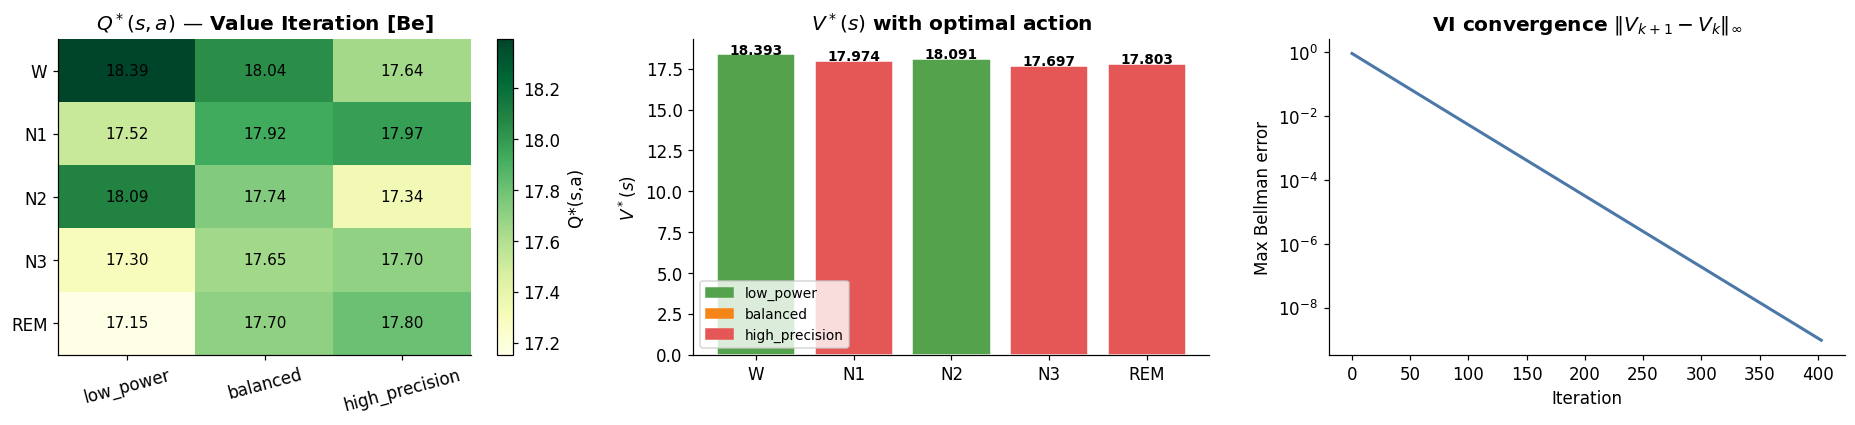

MDP artefacts saved.


In [4]:
Q_star = R_mdp + 0.95 * np.einsum('ija,j->ia', P_mdp, V_vi)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
# Q*(s,a) heatmap
im = axes[0].imshow(Q_star, cmap='YlGn', aspect='auto')
plt.colorbar(im, ax=axes[0], label='Q*(s,a)')
axes[0].set_xticks(range(N_ACTIONS)); axes[0].set_xticklabels(ACTION_NAMES, rotation=15)
axes[0].set_yticks(range(N_STAGES));  axes[0].set_yticklabels(STAGE_NAMES)
axes[0].set_title('$Q^*(s,a)$ — Value Iteration [Be]', fontweight='bold')
for i in range(N_STAGES):
    for j in range(N_ACTIONS):
        axes[0].text(j, i, f'{Q_star[i,j]:.2f}', ha='center', va='center', fontsize=10)
# V*(s) bar with action colours
ac = {'low_power':'#54a24b','balanced':'#f58518','high_precision':'#e45756'}
axes[1].bar(STAGE_NAMES, V_vi,
            color=[ac[ACTION_NAMES[pol_vi[s]]] for s in range(N_STAGES)],
            edgecolor='white')
for i, v in enumerate(V_vi):
    axes[1].text(i, v+0.02, f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
axes[1].set_title('$V^*(s)$ with optimal action', fontweight='bold')
axes[1].set_ylabel('$V^*(s)$')
axes[1].legend(handles=[mpatches.Patch(color=c,label=a) for a,c in ac.items()],
               fontsize=9)
# VI convergence
axes[2].semilogy(vi_hist, color='#4c78a8', lw=2)
axes[2].set_title('VI convergence $\\|V_{k+1}-V_k\\|_\\infty$', fontweight='bold')
axes[2].set_xlabel('Iteration'); axes[2].set_ylabel('Max Bellman error')
plt.tight_layout()
plt.savefig('fig6_mdp.png', bbox_inches='tight'); plt.show()

np.save('R_mdp.npy', R_mdp); np.save('V_vi.npy', V_vi)
np.save('pol_vi.npy', pol_vi); np.save('Q_star.npy', Q_star)
np.save('r_mdp_te.npy', np.array([r_mdp_te]))
print('MDP artefacts saved.')